# 10 · CURE against the 2025 multi-label and medical continual-learning baselines

Notebook 09 compared CURE with the agreed baselines, of which two were published in 2026 (MPT, RA-LDL). This notebook
adds three peer-reviewed methods from 2025 that address the parts of our problem the earlier baselines did not:

| Method | Venue | Why it is relevant |
|---|---|---|
| HCP | AAAI 2025 | multi-label class-incremental learning without replay; recalls missing old labels from the old model |
| RCLP | WACV 2025 | medical multi-label continual learning with new classes and a new dataset; label propagation, masking loss, feature distillation, small replay buffer |
| CRCL | MICCAI 2025 | medical class-incremental learning with pretrained models; conservative and radical learners fused at inference |

The adaptations to sigmoid outputs, our backbone and decoder, and the fixed-epoch protocol are documented in
`src/baselines2025.py`. RCLP replays 3% of the RFMiD 1.0 training images, as in its paper; every other update uses no
old images (Joint excepted). MOS (AAAI 2025) is not included: its adapter retrieval needs the task of each test image,
which is undefined when one fundus image holds old and new classes.

Stage A trains the three methods (15 runs each, resumable, about 3–5 h). Stage B rebuilds the full main table
(notebook 09's rows plus the new ones), applies CURE to every update and tests the pre-registered criteria.

**Send back:** the line under `SEND THIS BACK` in the last cell.

## 0. Configuration

In [2]:
QUICK = False                         # True: 1 seed, few epochs, smoke test only
TRAIN = dict(HCP=True, RCLP=True, CRCL=True)   # Stage A methods of this notebook; set False to postpone one

SEEDS = [0] if QUICK else [0, 1, 2]   # uses legacy_seed{s}.pt from notebook 02
K_FOLDS, SPLIT_SEED = 5, 0             # folds are read from notebook 04

CFG = dict(
    backbone="vit_base_patch14_dinov2.lvd142m",   # legacy backbone (timm name); DINOv2 ViT-B/14
    weights_file=None,        # local .pth/.safetensors instead of downloading, e.g. r"C:\weights\dinov2_vitb14.pth"
    pretrained=True,
    cache_size=256, crop=224, lora_r=8,
    bs=16, eval_bs=64, lr_lora=5e-4, lr_head=1e-3, wd=1e-4,
    legacy_epochs=4 if QUICK else 20, legacy_patience=5,
    epochs=4 if QUICK else 30, patience=6,
    kd_lambda=1.0, fd_alpha=1.0, fd_beta=5.0,              # focal distillation
    wise_alpha=0.5, ct_eps=0.0,
    min_pos=5, n_boot=50 if QUICK else 300,                 # evaluation
    alphas=(0.05, 0.10), ltt_delta=0.10,                    # certificates
    s1_epochs=2 if QUICK else 15,                           # fixed epochs for every update (validation fold unseen)
    joint_epochs=2 if QUICK else 20,                        # Joint: fresh model, as many epochs as the legacy model
    mpt_k=1.5, mpt_lambda=1.0,                              # MPT (AAAI 2026): new-class logit bias, distillation weight
    raldl_expand=5, raldl_rank=64, raldl_epochs=2 if QUICK else 20,   # RA-LDL (ICLR 2026): d1 = 5 d0, LRP rank
    hcp_pu=1.0,                                             # HCP (AAAI 2025): weight of the unknown-probing loss
    rclp_buffer=0.03, rclp_block=8, rclp_gamma=1.0,         # RCLP (WACV 2025): replay share, distilled block (0-based), weight
    crcl_lambda=50.0, crcl_ema=0.99,                        # CRCL (MICCAI 2025): feature-alignment weight, EMA consolidation
    shape_dup_thr=5,                                        # RFMiD 1.0 val images this close (pHash) to a pooled 2.0 image are not used for shapes
)
PLUG = ["FT", "KD", "FD", "WiSE", "OE", "MPT", "RA-LDL", "HCP", "RCLP", "CRCL", "Joint"]   # trained updates; CURE on each
COMPETITORS = ["MPT", "RA-LDL", "HCP", "RCLP", "CRCL"]   # published 2025-2026
OURS = "OE+CURE10"                       # pre-specified primary method row (strongest base in notebooks 06-08)
NI_MARGIN = 1.0                          # non-inferiority margin on new false alarms (NFR-, points)
import numpy as _np; GRID = _np.linspace(-8, 8, 801)   # threshold shifts (logit units)

# Hugging Face may be slow or blocked; uncomment to use the mirror (or set weights_file).
# import os; os.environ["HF_ENDPOINT"] = "https://hf-mirror.com"

## 1. Setup

In [3]:
import json, sys, time, copy
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src import config, audit, cure, cv, crc, frontier, certify, baselines2026 as b26, baselines2025 as b25

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = config.OUTPUT_DIR
CACHE, CKPT, RES = OUT / "cache", OUT / "checkpoints", OUT / "results"
for d in (CACHE, CKPT, RES):
    d.mkdir(parents=True, exist_ok=True)
CV04 = RES / ("cv_quick" if QUICK else "cv")        # notebook 04 results (folds, FD/CURE2/OPC-noCT)
RAW = RES / ("cv07_quick" if QUICK else "cv07")     # notebook 07: FT, WiSE, OE (read)
RAW8 = RES / ("cv08_quick" if QUICK else "cv08")    # notebook 08: FD (read)
RAW9 = RES / ("cv09_quick" if QUICK else "cv09")    # notebook 09: KD, MPT, Joint, RA-LDL (read)
RAW10 = RES / ("cv10_quick" if QUICK else "cv10")  # this notebook: HCP, RCLP, CRCL
RAW10.mkdir(parents=True, exist_ok=True)
assert (CV04 / "folds.csv").exists(), f"Run notebook 04 first: {CV04 / 'folds.csv'} not found"
need = [RAW / f"legacy__s{s}.npz" for s in SEEDS] + [RAW8 / f"FD__s{s}__f0.npz" for s in SEEDS] + [RAW9 / f"MPT__s{s}__f0.npz" for s in SEEDS]
miss = [p for p in need if not p.exists()]
assert not miss, f"Run notebooks 07, 08 and 09 first: {miss[0]} not found"
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
print("torch", torch.__version__)

device: cuda NVIDIA GeForce RTX 4060
torch 2.11.0+cu128


## 2. Manifests and label spaces

In [4]:
M = config.MANIFEST_DIR
man1 = {s: pd.read_csv(M / f"rfmid1_{s}.csv", dtype={"ID": str}) for s in config.SPLITS}
man2 = {s: pd.read_csv(M / f"rfmid2_{s}.csv", dtype={"ID": str}) for s in config.SPLITS}
space = json.load(open(M / "label_space.json"))

classes1 = space["rfmid1_classes"]                       # 45, legacy output order
new2 = space["new"]                                      # 12 RFMiD 2.0-only (2.0 column names)
UNION = classes1 + new2                                  # 57 = update model output space
N_OLD = len(classes1)
shared_map = space["shared_map"]                         # 1.0 name -> 2.0 column
SH = [UNION.index(c) for c in shared_map]                # union indices of shared classes
RT = [UNION.index(c) for c in space["retired"]]          # retired (1.0 only)
NW = list(range(N_OLD, len(UNION)))                      # new (2.0 only)
OLD = list(range(N_OLD))
print(f"union {len(UNION)} = shared {len(SH)} + retired {len(RT)} + new {len(NW)}")

union 57 = shared 38 + retired 7 + new 12


## 3. Pooled set, folds, RFMiD 1.0 val/test and the shape-fitting set

In [5]:
folds_df = pd.read_csv(CV04 / "folds.csv", dtype={"ID": str})
man2_all = pd.concat([pd.read_csv(M / f"rfmid2_{s}.csv", dtype={"ID": str}) for s in config.SPLITS], ignore_index=True)
pool = folds_df.merge(man2_all, on=["split", "ID"], how="left", validate="one_to_one")
folds, groups = pool["fold"].values, pool["group"].values

def label_arrays(man, dataset):
    n = len(man)
    Y = np.zeros((n, len(UNION)), dtype=np.float32)
    Mk = np.zeros_like(Y)
    if dataset == "rfmid1":
        Y[:, OLD] = man[classes1].values
        Mk[:, OLD] = 1
    else:
        for c1, c2 in shared_map.items():
            j = UNION.index(c1)
            Y[:, j], Mk[:, j] = man[c2].values, 1
        for c2 in new2:
            j = UNION.index(c2)
            Y[:, j], Mk[:, j] = man[c2].values, 1
    return Y, Mk

def load_split(man, dataset):
    paths = [CACHE / dataset / f"{s}_{i}.jpg" for s, i in zip(man["split"], man["ID"])]
    missing = [p for p in paths if not p.exists()]
    assert not missing, f"image cache incomplete (run notebook 02 first), e.g. {missing[0]}"
    Y, Mk = label_arrays(man, dataset)
    return {"X": cure.load_cache(paths), "Y": torch.from_numpy(Y), "M": torch.from_numpy(Mk)}

t0 = time.time()
P2 = load_split(pool, "rfmid2")
D1 = {s: load_split(man1[s], "rfmid1") for s in ("val", "test")}
Yp, Mp = P2["Y"].numpy(), P2["M"].numpy()
Y1t, M1t = D1["test"]["Y"].numpy(), D1["test"]["M"].numpy()
HR = UNION.index("HR") if "HR" in UNION else None
GROUPS = {"shared": SH, "new": NW, "all": SH + NW, "all_exHR": [c for c in SH + NW if c != HR]}
print(f"pooled RFMiD 2.0: {len(pool)} images in {K_FOLDS} folds; loaded in {time.time() - t0:.0f}s")

# Legacy-anchored shapes are fitted on RFMiD 1.0 val; drop its near-duplicates of pooled 2.0 images
fp1 = pd.read_csv(CACHE / "fingerprints_rfmid1.csv", dtype={"ID": str})
fp2 = pd.read_csv(CACHE / "fingerprints_rfmid2.csv", dtype={"ID": str})
v1val_fp = man1["val"][["split", "ID"]].merge(fp1, on=["split", "ID"], how="left")
pool_fp = pool[["split", "ID"]].merge(fp2, on=["split", "ID"], how="left")
assert v1val_fp["phash"].notna().all() and pool_fp["phash"].notna().all(), "fingerprints missing: rerun notebook 02"
dmin, _ = audit.hamming_min(v1val_fp["phash"], pool_fp["phash"])
KEEP1V = dmin > CFG["shape_dup_thr"]
Y1v, M1v = D1["val"]["Y"].numpy(), D1["val"]["M"].numpy()
print(f"RFMiD 1.0 val images for legacy-anchored shapes: {KEEP1V.sum()} of {len(KEEP1V)} "
      f"({(~KEEP1V).sum()} near-duplicates of pooled 2.0 images excluded)")

pooled RFMiD 2.0: 748 images in 5 folds; loaded in 3s
RFMiD 1.0 val images for legacy-anchored shapes: 631 of 640 (9 near-duplicates of pooled 2.0 images excluded)


## 4. Helpers and legacy models

In [6]:
def pad_union(l45):
    return np.concatenate([l45, np.zeros((len(l45), len(UNION) - N_OLD), dtype=l45.dtype)], 1)

def fresh_backbone():
    return cure.build_backbone(CFG["backbone"], CFG["pretrained"], CFG["crop"], CFG["lora_r"], CFG["weights_file"])

def raw_file(model, seed, fold):
    return RAW / f"{model}__s{seed}__f{fold}.npz"

def s2_file(model, seed):
    return S2DIR / f"{model}__s{seed}.npz"

def legacy_for_seed(seed):
    cure.set_seed(seed)
    net = cure.Net(fresh_backbone(), N_OLD)
    for n_, p in net.backbone.named_parameters():
        p.requires_grad = n_.endswith(".A") or n_.endswith(".B")
    ck = CKPT / f"legacy_seed{seed}{'_quick' if QUICK else ''}.pt"
    if ck.exists():
        net.load_trainable(torch.load(ck, map_location="cpu"))
        net.to(DEVICE)
        print(f"  legacy: loaded {ck.name}")
    else:
        print(f"  legacy checkpoint {ck.name} not found: training it on RFMiD 1.0 ...")
        tr1 = load_split(man1["train"], "rfmid1")
        cfg = dict(CFG, epochs=CFG["legacy_epochs"], patience=CFG["legacy_patience"])
        tr = {k: (v[:, :N_OLD] if k != "X" else v) for k, v in tr1.items()}
        va = {k: (v[:, :N_OLD] if k != "X" else v) for k, v in D1["val"].items()}
        cure.train(net, None, "legacy", tr, va, {}, cfg, DEVICE, OLD)
        torch.save(net.trainable_state(), ck)
        del tr1, tr
    for p in net.parameters():
        p.requires_grad = False
    net.eval()
    P = lambda X: cure.predict(net, None, X, "legacy", {}, CFG, DEVICE)
    l_v1val = P(D1["val"]["X"])
    thr45 = cure.f1_thresholds(l_v1val, D1["val"]["Y"].numpy()[:, :N_OLD], D1["val"]["M"].numpy()[:, :N_OLD], np.full(N_OLD, 0.5))
    return {"net": net, "l_v1val": l_v1val, "l_pool": pad_union(P(P2["X"])),
            "l_v1test": pad_union(P(D1["test"]["X"])),
            "thr": np.concatenate([thr45, np.full(len(UNION) - N_OLD, 0.5)])}

def subset(idx):
    return {k: P2[k][idx] for k in ("X", "Y", "M")}

v1_ret = lambda l: cure.macro_ap(l, Y1t, M1t, OLD)

def summarise(rows, keys):
    df = pd.DataFrame(rows)
    mean = df.groupby("variant")[keys].mean()
    sd = df.groupby("variant")[keys].std()
    fmt = lambda m, s: "nan" if pd.isna(m) else (f"{m:.3f}" if pd.isna(s) else f"{m:.3f} ± {s:.3f}")
    table = pd.DataFrame({k: [fmt(m, s) for m, s in zip(mean[k], sd[k])] for k in keys}, index=mean.index)
    return mean, table

def validity_table(info, mean):
    v = info.groupby("variant").agg(alpha=("alpha", "first"), method=("method", "first"), mean_lam=("lam", "mean"),
                                    mean_n_cal=("n_cal", "mean"),
                                    infeasible_share=("feasible", lambda f: float(1 - np.mean(f))),
                                    runs_above_alpha=("test_risk", lambda r: float(np.mean(r > info.loc[r.index, "alpha"]))))
    v["pooled_img_risk"] = (mean["img_risk_%"] / 100).reindex(v.index)
    return v

def bootstrap(FS, curve_models, points, seeds, n_img, contrasts, n_boot, rs=0):
    """Gap vs envelope of every point, and paired NFR- differences (contrasts: name -> (a, b), a - b)."""
    est_g, est_x, est_y = certify.envelope_stats(FS, curve_models, points, seeds, GRID)
    rng = np.random.default_rng(rs)
    G, X = [], []
    for _ in range(n_boot):
        w = np.bincount(rng.integers(0, n_img, n_img), minlength=n_img).astype(float)
        g, x, _ = certify.envelope_stats(FS, curve_models, points, seeds, GRID, w)
        G.append(g)
        X.append(x)
    G, X = pd.DataFrame(G), pd.DataFrame(X)
    gap = {p: certify.ci(est_g[p], G[p]) for p in points}
    con = {k: certify.ci(est_x[a] - est_x[b], X[a] - X[b]) for k, (a, b) in contrasts.items()}
    return gap, con

KEYS = ["mAP_all", "NFR+_%", "NFR-_%", "NFR_%", "img_risk_%", f"regressed_classes_min{CFG['min_pos']}"]
TAGS = [int(round(100 * a)) for a in CFG["alphas"]]

def fd_file(seed, fold):
    return RAW8 / f"FD__s{seed}__f{fold}.npz"

def f9(model, seed, fold):
    return RAW9 / f"{model}__s{seed}__f{fold}.npz"

def load_raw(model, seed, fold):
    if model == "FD":
        return np.load(fd_file(seed, fold))
    if model in ("FT", "WiSE", "OE"):
        return np.load(raw_file(model, seed, fold))
    if model in ("HCP", "RCLP", "CRCL"):
        return np.load(f10(model, seed, fold))
    return np.load(f9(model, seed, fold))

def f10(model, seed, fold):
    return RAW10 / f"{model}__s{seed}__f{fold}.npz"

def fresh_net():
    net = cure.Net(fresh_backbone(), len(UNION))
    for n_, p in net.backbone.named_parameters():
        p.requires_grad = n_.endswith(".A") or n_.endswith(".B")
    return net

def bootstrap2(FS, curve_models, points, seeds, n_img, contrasts, n_boot, rs=0):
    """Gap vs envelope of every point, and paired differences a - b in NFR- and NFR+ (points)."""
    est_g, est_x, est_y = certify.envelope_stats(FS, curve_models, points, seeds, GRID)
    rng = np.random.default_rng(rs)
    G, X, Yb = [], [], []
    for _ in range(n_boot):
        w = np.bincount(rng.integers(0, n_img, n_img), minlength=n_img).astype(float)
        g, x, y = certify.envelope_stats(FS, curve_models, points, seeds, GRID, w)
        G.append(g)
        X.append(x)
        Yb.append(y)
    G, X, Yb = pd.DataFrame(G), pd.DataFrame(X), pd.DataFrame(Yb)
    gap = {p: certify.ci(est_g[p], G[p]) for p in points}
    cx = {k: certify.ci(est_x[a] - est_x[b], X[a] - X[b]) for k, (a, b) in contrasts.items()}
    cy = {k: certify.ci(est_y[a] - est_y[b], Yb[a] - Yb[b]) for k, (a, b) in contrasts.items()}
    return gap, cx, cy

def per_class_miss(VAR, LEG, names, Y, M, cls_idx, min_caught=5):
    """Per class: mean number of legacy-detected positives per seed, and % of them each variant misses."""
    rows = []
    for j, c in enumerate(cls_idx):
        rec = {"class": UNION[c]}
        for n in names:
            miss = tot = 0
            for s in SEEDS:
                L, T = VAR[(n, s)]
                Lo, to = LEG[s]
                caught = crc.legacy_caught(Lo, to, Y, M, cls_idx)[:, j]
                pred = L[:, c] >= cure.logit(T[:, c])
                miss += int((caught & ~pred).sum())
                tot += int(caught.sum())
            rec["n_caught"] = tot / len(SEEDS)
            rec[n] = 100 * miss / tot if tot else np.nan
        rows.append(rec)
    df = pd.DataFrame(rows)
    return df[df["n_caught"] >= min_caught].sort_values("n_caught", ascending=False).reset_index(drop=True)

def class_summary(df, base, ours):
    d = df[ours] - df[base]
    return {"n_classes": int(len(df)), "worst_class_miss_%": {base: round(float(df[base].max()), 1), ours: round(float(df[ours].max()), 1)},
            "classes_worse_by_>5pts": df.loc[d > 5, "class"].tolist(),
            "classes_better_by_>5pts": int((d < -5).sum())}

KEYS8 = ["mAP_shared", "mAP_all", "NFR+_%", "NFR-_%", "img_risk_%", f"regressed_classes_min{CFG['min_pos']}"]

KEYS9 = ["mAP_shared", "mAP_new", "mAP_all", "NFR+_%", "NFR-_%", "img_risk_%", f"regressed_classes_min{CFG['min_pos']}"]

## 5. Stage A: train HCP, RCLP and CRCL per fold (resumable)

Same folds, seeds (`seed*100 + fold`), initialisation from the legacy model and fixed-epoch protocol as notebooks
07-09. Saved per method and fold: logits on the validation fold, the test fold and RFMiD 1.0 val.

In [7]:
import math
cfg1 = dict(CFG, epochs=CFG["s1_epochs"])
quiet = lambda *a: None
tr1 = None
for seed in SEEDS:
    todo = [m for m in ("HCP", "RCLP", "CRCL") if TRAIN[m] and not all(f10(m, seed, k).exists() for k in range(K_FOLDS))]
    if not todo:
        print(f"seed {seed}: nothing to train")
        continue
    print(f"\n=== seed {seed}: {todo} ===")
    pack = legacy_for_seed(seed)
    legacy = pack["net"]
    ctx = {"shared_idx": SH, "retired_idx": RT, "old_idx": OLD, "mid_block": CFG["rclp_block"],
           "thr_logit": torch.tensor(cure.logit(pack["thr"]), dtype=torch.float32, device=DEVICE),
           "thr_prob": torch.tensor(pack["thr"], dtype=torch.float32, device=DEVICE)}
    # HCP recall enhancement: legacy mean confidence on positives of each retired class (RFMiD 1.0 val)
    pv = 1 / (1 + np.exp(-pack["l_v1val"]))
    hcp_thr = [float(pv[Y1v[:, c] == 1, c].mean()) if (Y1v[:, c] == 1).any() else float(pack["thr"][c]) for c in RT]
    hcp_w = torch.ones(len(UNION), device=DEVICE)
    hcp_w[NW] = math.sqrt(len(UNION) / len(NW))
    if "RCLP" in todo:
        if tr1 is None:
            tr1 = load_split(man1["train"], "rfmid1")
        n_buf = max(1, int(round(CFG["rclp_buffer"] * len(tr1["X"]))))
        buf_idx = np.random.default_rng(seed).choice(len(tr1["X"]), n_buf, replace=False)
        buf = {key: tr1[key][buf_idx] for key in ("X", "Y", "M")}       # masks cover the 45 legacy labels only
        print(f"  RCLP replay buffer: {n_buf} RFMiD 1.0 training images")
    for k in range(K_FOLDS):
        te = np.where(folds == k)[0]
        va = np.where(folds == (k + 1) % K_FOLDS)[0]
        tr = np.where((folds != k) & (folds != (k + 1) % K_FOLDS))[0]
        def save(name, model):
            P = lambda X: cure.predict(model, None, X, "FT", {}, CFG, DEVICE)
            np.savez(f10(name, seed, k), Lva=P(P2["X"][va]), Lte=P(P2["X"][te]), L1v=P(D1["val"]["X"]))
        t0 = time.time()
        if "HCP" in todo and not f10("HCP", seed, k).exists():
            cure.set_seed(seed * 100 + k)
            net = cure.expand_from_legacy(legacy, len(UNION), N_OLD)
            net.decoder = b25.HCPDecoder(net.decoder, N_OLD)
            ctx_h = dict(ctx, hcp_thr=torch.tensor(hcp_thr, dtype=torch.float32, device=DEVICE), hcp_w=hcp_w,
                         hcp_decoder=net.decoder)
            cure.train(net, legacy, "HCP", subset(tr), None, ctx_h, cfg1, DEVICE, SH + NW, log=quiet,
                       forward_fn=b25.hcp_forward, loss_fn=b25.hcp_loss)
            save("HCP", net)
            del net, ctx_h
        if "RCLP" in todo and not f10("RCLP", seed, k).exists():
            cure.set_seed(seed * 100 + k)
            net = cure.expand_from_legacy(legacy, len(UNION), N_OLD)
            new = subset(tr)
            reps = int(math.ceil(len(tr) / n_buf))                          # about 50% replay per epoch
            trr = {key: torch.cat([new[key]] + [buf[key]] * reps)[: 2 * len(tr)] for key in ("X", "Y", "M")}
            cure.train(net, legacy, "RCLP", trr, None, ctx, cfg1, DEVICE, SH + NW, log=quiet,
                       forward_fn=b25.rclp_forward, loss_fn=b25.rclp_loss)
            save("RCLP", net)
            del net, trr
        if "CRCL" in todo and not f10("CRCL", seed, k).exists():
            cure.set_seed(seed * 100 + k)
            net = cure.expand_from_legacy(legacy, len(UNION), N_OLD)
            cure.train(net, legacy, "CRCL", subset(tr), None, ctx, cfg1, DEVICE, SH + NW, log=quiet,
                       forward_fn=b25.crcl_forward, loss_fn=b25.crcl_loss)
            fused = b25.CRCLNet(net, b25.ema_conservative(legacy, net, CFG["crcl_ema"]), N_OLD).to(DEVICE).eval()
            save("CRCL", fused)
            del net, fused
        print(f"  fold {k}: done in {(time.time() - t0) / 60:.1f} min")
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    del pack, legacy


=== seed 0: ['HCP', 'RCLP', 'CRCL'] ===


  legacy: loaded legacy_seed0.pt
  RCLP replay buffer: 58 RFMiD 1.0 training images


c:\Users\Sajjad\Documents\Documents\paper-1\paper-1\src\cure.py:346: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


  fold 0: done in 5.2 min
  fold 1: done in 5.3 min
  fold 2: done in 5.4 min
  fold 3: done in 5.3 min
  fold 4: done in 5.0 min

=== seed 1: ['HCP', 'RCLP', 'CRCL'] ===
  legacy: loaded legacy_seed1.pt
  RCLP replay buffer: 58 RFMiD 1.0 training images
  fold 0: done in 4.9 min
  fold 1: done in 4.9 min
  fold 2: done in 5.0 min
  fold 3: done in 5.0 min
  fold 4: done in 5.0 min

=== seed 2: ['HCP', 'RCLP', 'CRCL'] ===
  legacy: loaded legacy_seed2.pt
  RCLP replay buffer: 58 RFMiD 1.0 training images
  fold 0: done in 4.9 min
  fold 1: done in 4.9 min
  fold 2: done in 5.0 min
  fold 3: done in 5.0 min
  fold 4: done in 4.9 min


## 6. Stage B: every row of the main table (no training)

- `Legacy`: the deployed legacy model (by definition no flips). `Legacy-recal`: legacy logits, F1 thresholds re-fitted on
  the 2.0 validation fold. `Select`: per shared class, legacy or FT by validation AP (retired classes keep the legacy);
  Select uses the validation fold to choose, so CURE is not applied on top of it.
- For every trained update `X` in PLUG: `X` (F1 thresholds on the validation fold), `X+CURE10`, `X+CURE5` and
  `X+CURE-LTT10` (CURE thresholds fitted on RFMiD 1.0 val, certificate calibrated on the full validation fold).

In [8]:
VAR, INFO, LEG = {}, [], {}
for seed in SEEDS:
    z = np.load(RAW / f"legacy__s{seed}.npz")
    L_old, thr_old, L1v_old = z["L"], z["thr"], z["L1v"]
    LEG[seed] = (L_old, thr_old)
    fallback = np.where(np.arange(len(UNION)) < N_OLD, thr_old, 0.5)
    caught_all = crc.legacy_caught(L_old, thr_old, Yp, Mp, SH)
    VAR[("Legacy", seed)] = (L_old, np.broadcast_to(thr_old, L_old.shape).copy())
    acc = {}
    for k in range(K_FOLDS):
        te = np.where(folds == k)[0]
        va = np.where(folds == (k + 1) % K_FOLDS)[0]
        Yv, Mv, lo_va = Yp[va], Mp[va], L_old[va]
        acc.setdefault("Legacy-recal", []).append((te, L_old[te], cv.plain_thresholds(lo_va, Yv, Mv, fallback)))
        ft = load_raw("FT", seed, k)
        Ls_va, _ = cure.per_class_select(ft["Lva"], lo_va, Yv, Mv, ft["Lva"], lo_va, SH, RT)
        Ls_te, _ = cure.per_class_select(ft["Lva"], lo_va, Yv, Mv, ft["Lte"], L_old[te], SH, RT)
        acc.setdefault("Select", []).append((te, Ls_te, cv.plain_thresholds(Ls_va, Yv, Mv, fallback)))
        for m in PLUG:
            try:
                r = load_raw(m, seed, k)
            except FileNotFoundError:
                continue
            Lva, Lte, L1v = r["Lva"], r["Lte"], r["L1v"]
            plain = cv.plain_thresholds(Lva, Yv, Mv, fallback)
            s = certify.fit_shape("ct", L1v[KEEP1V], Y1v[KEEP1V], M1v[KEEP1V], L1v_old[KEEP1V], thr_old, SH, fallback, None, CFG["ct_eps"])
            base = plain.copy()
            base[SH] = s[SH]
            caught_v = crc.legacy_caught(lo_va, thr_old, Yv, Mv, SH)
            acc.setdefault(m, []).append((te, Lte, plain))
            for a, tag, meth in [(0.10, "10", "CRC"), (0.05, "5", "CRC"), (0.10, "-LTT10", "LTT")]:
                if meth == "CRC":
                    lam, n_cal, ok = crc.calibrate(Lva, base, caught_v, SH, a, GRID)
                else:
                    lam, n_cal, ok = certify.ltt_calibrate(Lva, base, caught_v, SH, a, CFG["ltt_delta"], GRID)
                t = crc.shift_thresholds(base, SH, lam)
                name = f"{m}+CURE{tag}"
                acc.setdefault(name, []).append((te, Lte, t))
                risk = crc.image_losses(Lte, t, caught_all[te], SH)
                INFO.append({"variant": name, "seed": seed, "fold": k, "alpha": a, "method": meth, "lam": lam, "n_cal": n_cal,
                             "feasible": bool(ok), "test_risk": float(risk.mean()) if len(risk) else np.nan})
    for name, parts in acc.items():
        if len(parts) != K_FOLDS:
            print(f"  skipped {name} (seed {seed}): only {len(parts)} of {K_FOLDS} folds available")
            continue
        L = np.zeros((len(pool), len(UNION)), np.float32)
        T = np.zeros_like(L)
        for te, Lte, t in parts:
            L[te], T[te] = Lte, t[None, :]
        VAR[(name, seed)] = (L, T)
info = pd.DataFrame(INFO)
NAMES = [n for n in ["Legacy", "Legacy-recal", "Select"] + [f"{m}{s}" for m in PLUG for s in ("", "+CURE10", "+CURE5", "+CURE-LTT10")]
         if all((n, s) in VAR for s in SEEDS)]
print(f"{len(NAMES)} rows:", NAMES)

47 rows: ['Legacy', 'Legacy-recal', 'Select', 'FT', 'FT+CURE10', 'FT+CURE5', 'FT+CURE-LTT10', 'KD', 'KD+CURE10', 'KD+CURE5', 'KD+CURE-LTT10', 'FD', 'FD+CURE10', 'FD+CURE5', 'FD+CURE-LTT10', 'WiSE', 'WiSE+CURE10', 'WiSE+CURE5', 'WiSE+CURE-LTT10', 'OE', 'OE+CURE10', 'OE+CURE5', 'OE+CURE-LTT10', 'MPT', 'MPT+CURE10', 'MPT+CURE5', 'MPT+CURE-LTT10', 'RA-LDL', 'RA-LDL+CURE10', 'RA-LDL+CURE5', 'RA-LDL+CURE-LTT10', 'HCP', 'HCP+CURE10', 'HCP+CURE5', 'HCP+CURE-LTT10', 'RCLP', 'RCLP+CURE10', 'RCLP+CURE5', 'RCLP+CURE-LTT10', 'CRCL', 'CRCL+CURE10', 'CRCL+CURE5', 'CRCL+CURE-LTT10', 'Joint', 'Joint+CURE10', 'Joint+CURE5', 'Joint+CURE-LTT10']


## 7. Results and certificate validity

In [9]:
rows = []
blocks = [np.where(folds == k)[0] for k in range(K_FOLDS)]
for (name, seed), (L, T) in VAR.items():
    if name not in NAMES:
        continue
    L_old, thr_old = LEG[seed]
    res = cv.pooled_metrics(L, T, L_old, thr_old, Yp, Mp, GROUPS, SH, CFG["min_pos"])
    res.pop("per_class_ap")
    res["NFR-_%"] = frontier.point(frontier.flip_sets(L, T, L_old, thr_old, Yp, Mp, SH))[0]
    res["img_risk_%"] = 100 * certify.pooled_image_risk(L, T, crc.legacy_caught(L_old, thr_old, Yp, Mp, SH), SH, blocks)
    rows.append(dict(res, variant=name, seed=seed))
mean, table = summarise(rows, KEYS9)
sd = pd.DataFrame(rows).groupby("variant")[KEYS9].std().reindex(NAMES)
mean, table = mean.reindex(NAMES), table.reindex(NAMES)
table.to_csv(RES / ("main09_table_quick.csv" if QUICK else "main09_table.csv"))
display(table)
valid = validity_table(info, mean)
display(valid.round(3))

,mAP_shared,mAP_new,mAP_all,NFR+_%,NFR-_%,img_risk_%,regressed_classes_min5
variant,,,,,,,
Legacy,0.183 ± 0.004,0.006 ± 0.000,0.143 ± 0.003,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
Legacy-recal,0.183 ± 0.004,0.006 ± 0.000,0.143 ± 0.003,6.223 ± 1.117,11.854 ± 0.300,19.504 ± 2.159,0.000 ± 0.000
Select,0.331 ± 0.018,0.329 ± 0.024,0.330 ± 0.010,10.912 ± 1.294,4.116 ± 0.350,34.305 ± 1.311,1.000 ± 0.000
FT,0.350 ± 0.021,0.329 ± 0.024,0.346 ± 0.012,11.466 ± 2.513,6.720 ± 0.745,36.026 ± 4.988,0.667 ± 1.155
FT+CURE10,0.350 ± 0.021,0.329 ± 0.024,0.346 ± 0.012,2.941 ± 1.023,21.567 ± 8.561,8.751 ± 2.424,0.667 ± 1.155
FT+CURE5,0.350 ± 0.021,0.329 ± 0.024,0.346 ± 0.012,1.449 ± 0.822,41.407 ± 8.455,4.223 ± 2.241,0.667 ± 1.155
FT+CURE-LTT10,0.350 ± 0.021,0.329 ± 0.024,0.346 ± 0.012,0.853 ± 0.925,51.329 ± 11.364,2.419 ± 2.394,0.667 ± 1.155
KD,0.363 ± 0.013,0.356 ± 0.020,0.361 ± 0.013,9.847 ± 1.677,6.169 ± 0.317,31.432 ± 3.277,0.333 ± 0.577
KD+CURE10,0.363 ± 0.013,0.356 ± 0.020,0.361 ± 0.013,2.941 ± 0.965,13.917 ± 12.513,8.769 ± 2.262,0.333 ± 0.577


,alpha,method,mean_lam,mean_n_cal,infeasible_share,runs_above_alpha,pooled_img_risk
variant,,,,,,,
CRCL+CURE-LTT10,0.10,LTT,0.548,45.667,0.0,0.000,0.025
CRCL+CURE10,0.10,CRC,-0.807,45.667,0.0,0.400,0.076
CRCL+CURE5,0.05,CRC,0.111,45.667,0.0,0.133,0.034
FD+CURE-LTT10,0.10,LTT,0.937,45.667,0.0,0.000,0.027
FD+CURE10,0.10,CRC,-0.169,45.667,0.0,0.200,0.072
FD+CURE5,0.05,CRC,0.576,45.667,0.0,0.267,0.034
FT+CURE-LTT10,0.10,LTT,2.588,45.667,0.0,0.067,0.024
FT+CURE10,0.10,CRC,-0.468,45.667,0.0,0.467,0.088
FT+CURE5,0.05,CRC,1.512,45.667,0.0,0.333,0.042


## 8. Trade-off envelope and paired contrasts (image bootstrap)

Curves: every trained update in PLUG (now including HCP, RCLP and CRCL) plus Select.

In [10]:
CURVES = [m for m in PLUG + ["Select"] if m in NAMES]
POINTS = [n for n in NAMES if n != "Legacy"]
FS = {(n, s): frontier.flip_sets(*VAR[(n, s)], LEG[s][0], LEG[s][1], Yp, Mp, SH) for n in POINTS for s in SEEDS}
CON = {}
for m in PLUG:
    if f"{m}+CURE10" in NAMES:
        CON[f"PLUGIN {m}+CURE10 vs {m}"] = (f"{m}+CURE10", m)
        CON[f"PLUGIN {m}+CURE5 vs {m}"] = (f"{m}+CURE5", m)
for b in [n for n in NAMES if n not in ("Legacy", OURS)]:
    if "+CURE" not in b or b.endswith("CURE10") and b.split("+")[0] in tuple(COMPETITORS):
        CON[f"MAIN {OURS} vs {b}"] = (OURS, b)
t0 = time.time()
gap, cx, cy = bootstrap2(FS, CURVES, POINTS, SEEDS, len(pool), CON, CFG["n_boot"], rs=0)
print(f"bootstrap: {(time.time() - t0) / 60:.1f} min")
display(pd.Series(gap, name="gap vs envelope").to_frame())
display(pd.DataFrame({"d_NFR+": cy, "d_NFR-": cx}))

bootstrap: 1.2 min


,gap vs envelope
Legacy-recal,"[1.725, 1.137, 2.964]"
Select,"[2.071, 1.463, 3.414]"
FT,"[4.646, 3.722, 5.826]"
FT+CURE10,"[0.19, -0.426, 1.301]"
FT+CURE5,"[0.512, 0.157, 1.198]"
FT+CURE-LTT10,"[0.549, 0.208, 0.991]"
KD,"[2.812, 2.01, 3.867]"
KD+CURE10,"[-2.387, -3.289, -1.108]"
KD+CURE5,"[-0.895, -1.242, 0.076]"
KD+CURE-LTT10,"[-0.363, -0.727, 0.361]"


,d_NFR+,d_NFR-
PLUGIN FT+CURE10 vs FT,"[-8.525, -9.972, -7.278]","[14.847, 14.25, 15.363]"
PLUGIN FT+CURE5 vs FT,"[-10.017, -11.474, -8.526]","[34.686, 33.991, 35.298]"
PLUGIN KD+CURE10 vs KD,"[-6.905, -8.178, -5.617]","[7.748, 7.467, 8.04]"
PLUGIN KD+CURE5 vs KD,"[-8.525, -9.918, -7.228]","[20.819, 20.294, 21.296]"
PLUGIN FD+CURE10 vs FD,"[-7.246, -8.502, -6.001]","[8.995, 8.566, 9.39]"
PLUGIN FD+CURE5 vs FD,"[-8.397, -9.744, -7.025]","[24.904, 24.435, 25.244]"
PLUGIN WiSE+CURE10 vs WiSE,"[-5.115, -6.685, -3.738]","[-0.554, -0.897, -0.264]"
PLUGIN WiSE+CURE5 vs WiSE,"[-6.777, -8.189, -5.34]","[7.196, 6.809, 7.552]"
PLUGIN OE+CURE10 vs OE,"[-5.371, -6.531, -4.222]","[-2.056, -2.279, -1.827]"
PLUGIN OE+CURE5 vs OE,"[-6.777, -7.899, -5.565]","[5.253, 4.922, 5.613]"


## 9. Figure: CURE against every baseline's trade-off curve

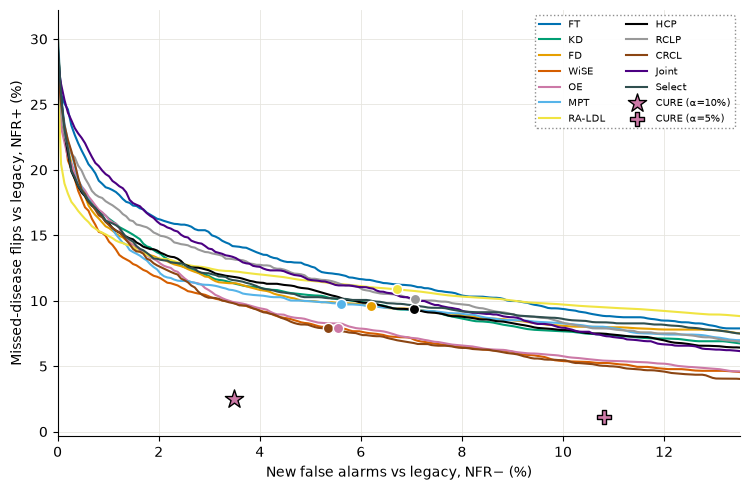

In [11]:
OI = ["#0072B2", "#009E73", "#E69F00", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#000000", "#999999",
      "#8B4513", "#4B0082", "#2F4F4F"]
colors = dict(zip(CURVES, OI))
pts = [p for p in [OURS, "OE+CURE5"] + COMPETITORS + ["FD", "OE"] if p in mean.index]
xs_all = [mean.loc[p, "NFR-_%"] for p in pts]
lo, hi = 0.0, 1.25 * max(xs_all + [10.0])
xs = np.linspace(lo, hi, 200)
fig, ax = plt.subplots(figsize=(7.6, 5.0))
for c in CURVES:
    cs = [frontier.curve(FS[(c, s)], GRID) for s in SEEDS]
    ax.plot(xs, np.mean([[frontier.frontier_at(*cc, v) for v in xs] for cc in cs], axis=0), color=colors[c], lw=1.5, label=c)
mk = {OURS: ("*", 190, "CURE (α=10%)"), "OE+CURE5": ("P", 110, "CURE (α=5%)")}
for p in pts:
    b = p.split("+")[0]
    marker, size, lab = mk.get(p, ("o", 55, None))
    ax.scatter(mean.loc[p, "NFR-_%"], mean.loc[p, "NFR+_%"], marker=marker, s=size, color=colors.get(b, "#000000"),
               edgecolor="black" if p in mk else "white", lw=1, zorder=6, label=lab)
ax.set_xlim(lo, hi)
ax.set_xlabel("New false alarms vs legacy, NFR− (%)")
ax.set_ylabel("Missed-disease flips vs legacy, NFR+ (%)")
ax.grid(color="#e6e5df", lw=0.6)
ax.spines[["top", "right"]].set_visible(False)
leg = ax.legend(fontsize=7.5, loc="best", frameon=True, framealpha=0.95, ncol=2)
leg.get_frame().set_linestyle(":")
leg.get_frame().set_edgecolor("#888888")
fig.tight_layout()
fig.savefig(RES / ("main10_frontier_quick.png" if QUICK else "main10_frontier.png"), dpi=300)
plt.show()

## 10. Pre-registered criteria and verdict

- **E1 · beats every 2025-2026 competitor**: for each of MPT, RA-LDL, HCP, RCLP and CRCL, CURE (OE+CURE10) has fewer
  missed-disease flips (paired CI below 0) with new false alarms non-inferior (upper CI < +1 point).
- **E2 · plug-in on the new competitors**: X+CURE10 has fewer missed-disease flips than X for HCP, RCLP and CRCL.
- **E3 · beats every baseline's threshold tuning**: CURE's gap vs the envelope of all update curves (now including HCP,
  RCLP and CRCL) has a CI entirely below 0.
- **E4 · certificates hold**: every X+CURE10 / X+CURE5 row has pooled test image risk ≤ α + 0.5 points.

Verdict: **REVISE** if E4 fails; **CONFIRMED** if E1, E3 and E4 pass; otherwise **REVIEW** (names what failed; a
competitor that beats CURE on both error types is reported by name).

In [12]:
H = {}
def alpha_of(name):
    return 10 if name.endswith("CURE10") else 5
e1 = {}
for comp in COMPETITORS:
    key = f"MAIN {OURS} vs {comp}"
    if key in cy:
        e1[comp] = {"pass": bool(cy[key][2] < 0 and cx[key][2] < NI_MARGIN), "d_NFR+": cy[key], "d_NFR-": cx[key]}
H["E1_beats_2025_2026"] = bool(len(e1) == len(COMPETITORS) and all(v["pass"] for v in e1.values()))
H["E1_detail"] = e1
e2 = {m: {"d_NFR+": cy[f"PLUGIN {m}+CURE10 vs {m}"], "d_NFR-": cx[f"PLUGIN {m}+CURE10 vs {m}"]}
      for m in ("HCP", "RCLP", "CRCL") if f"PLUGIN {m}+CURE10 vs {m}" in cy}
H["E2_plugin_new"] = bool(len(e2) == 3 and all(v["d_NFR+"][2] < 0 for v in e2.values()))
H["E2_detail"] = e2
H["E3_below_envelope"] = bool(gap[OURS][2] < 0)
H["E3_gap"] = gap[OURS]
cert = {n: float(mean.loc[n, "img_risk_%"]) for n in NAMES if n.endswith(("CURE10", "CURE5"))}
H["E4_certificates_hold"] = bool(all(r <= alpha_of(n) + 0.5 for n, r in cert.items()))
H["E4_worst"] = max(cert, key=lambda n: cert[n] - alpha_of(n))
stronger = [c for c, v in e1.items() if v["d_NFR+"][1] > 0 and v["d_NFR-"][1] > 0]
H["competitors_better_on_both"] = stronger
H["competitors_plus_CURE_vs_OURS"] = {f"{c}+CURE10": {"d_NFR+": cy.get(f"MAIN {OURS} vs {c}+CURE10"), "d_NFR-": cx.get(f"MAIN {OURS} vs {c}+CURE10")}
                                      for c in COMPETITORS}
fails = [k for k in ("E1_beats_2025_2026", "E3_below_envelope") if not H[k]]
verdict = ("REVISE (a certificate exceeded its alpha)" if not H["E4_certificates_hold"]
           else "CONFIRMED" if not fails else "REVIEW: " + ", ".join(fails) + (f"; better on both: {stronger}" if stronger else ""))

def compact(names):
    out = {}
    for n in names:
        r, s = mean.loc[n], sd.loc[n]
        out[n] = {"mAPsh": round(float(r["mAP_shared"]), 3), "mAPnew": round(float(r["mAP_new"]), 3), "mAP": round(float(r["mAP_all"]), 3),
                  "NFR+": [round(float(r["NFR+_%"]), 2), round(float(s["NFR+_%"]), 2)],
                  "NFR-": [round(float(r["NFR-_%"]), 2), round(float(s["NFR-_%"]), 2)],
                  "risk": round(float(r["img_risk_%"]), 2), "regr": round(float(r[KEYS9[-1]]), 2)}
    return out
send = {"notebook": "10_cure_2025_baselines", "quick_mode": QUICK, "seeds": SEEDS, "n_boot": CFG["n_boot"], "trained": TRAIN,
        "means_format": "NFR as [mean, sd over seeds]", "validity_format": "[infeasible share, runs above alpha, mean calibration images]",
        "means": compact(NAMES), "gap": gap, "d_NFR+": cy, "d_NFR-": cx,
        "validity": {n: [round(float(r["infeasible_share"]), 2), round(float(r["runs_above_alpha"]), 2), round(float(r["mean_n_cal"]), 1)]
                     for n, r in valid.iterrows()},
        "hypotheses": H, "verdict": verdict}
(RES / ("main10_summary_quick.json" if QUICK else "main10_summary.json")).write_text(json.dumps(send, indent=1, default=str))
print("=" * 30, "SEND THIS BACK", "=" * 30)
print(json.dumps(send, default=str))

============================== SEND THIS BACK ==============================
{"notebook": "10_cure_2025_baselines", "quick_mode": false, "seeds": [0, 1, 2], "n_boot": 300, "trained": {"HCP": true, "RCLP": true, "CRCL": true}, "means_format": "NFR as [mean, sd over seeds]", "validity_format": "[infeasible share, runs above alpha, mean calibration images]", "means": {"Legacy": {"mAPsh": 0.183, "mAPnew": 0.006, "mAP": 0.143, "NFR+": [0.0, 0.0], "NFR-": [0.0, 0.0], "risk": 0.0, "regr": 0.0}, "Legacy-recal": {"mAPsh": 0.183, "mAPnew": 0.006, "mAP": 0.143, "NFR+": [6.22, 1.12], "NFR-": [11.85, 0.3], "risk": 19.5, "regr": 0.0}, "Select": {"mAPsh": 0.331, "mAPnew": 0.329, "mAP": 0.33, "NFR+": [10.91, 1.29], "NFR-": [4.12, 0.35], "risk": 34.31, "regr": 1.0}, "FT": {"mAPsh": 0.35, "mAPnew": 0.329, "mAP": 0.346, "NFR+": [11.47, 2.51], "NFR-": [6.72, 0.74], "risk": 36.03, "regr": 0.67}, "FT+CURE10": {"mAPsh": 0.35, "mAPnew": 0.329, "mAP": 0.346, "NFR+": [2.94, 1.02], "NFR-": [21.57, 8.56], "risk":